# 09 — Evaluación y Comparación de Modelos
## Pipeline CAD-TBX11K | Diagnóstico Asistido por Computador en Tuberculosis

Este notebook evalúa los cinco modelos con las **predicciones out-of-fold (OOF)** de la
validación cruzada del notebook 08 sobre las **8256 imágenes**. No hay hold-out ni test
separado: la estimación es la CV OOF.

### Métricas
- Accuracy, balanced accuracy, precision, recall y F1 (macro y weighted).
- Métricas por clase (`health`, `sick`, `tb`).
- AUC-ROC por clase (One-vs-Rest) y **Average Precision (AP)** de `tb`.
- Intervalos de confianza por bootstrap y McNemar con Holm.
- Calibración de `tb` (Brier + curva).

### Protocolo
1. Cargar las predicciones y scores OOF del notebook 08.
2. Evaluar las 8256 imágenes (cada una predicha exactamente una vez).
3. Comparar modelos y analizar la incertidumbre.
4. Recomendar el modelo elegido por la CV del 08.

### Flujo

```
data/08_oof_predicciones.csv
data/08_oof_scores.npz
models/08_manifest.json
         |
         v
 Metricas globales + por clase + AUC/AP
         |
         v
 Matrices de confusion + curvas ROC/AP
         |
         v
 Bootstrap + McNemar (global y tb) + calibracion
         |
         v
 Recomendacion final
```


## 0. Configuración del entorno


In [20]:
# Se configura el path del proyecto y se importan las librerías de evaluación.
# Referencias:
#   metricas: https://scikit-learn.org/stable/modules/model_evaluation.html
#   calibracion: https://scikit-learn.org/stable/modules/calibration.html

import sys, os, warnings, json
warnings.filterwarnings('ignore')

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
)
from sklearn.calibration import calibration_curve

_CWD = os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(_CWD, '..')) if os.path.basename(_CWD) == 'notebooks' else _CWD
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.features import model_feature_columns
from src.visualization import set_publication_style

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CLASS_NAMES = ['health', 'sick', 'tb']
N_BOOTSTRAP = 1000

DATA_DIR    = Path(PROJECT_ROOT) / 'data'
MODELS_DIR  = Path(PROJECT_ROOT) / 'models'
REPORTS_DIR = Path(PROJECT_ROOT) / 'reports'
REPORTS_DIR.mkdir(exist_ok=True)

set_publication_style()
print('Entorno configurado correctamente.')


Entorno configurado correctamente.


## 1. Carga de las predicciones out-of-fold


In [21]:
# Se cargan las predicciones y scores OOF del notebook 08.
# Cada imagen fue predicha exactamente una vez por el modelo de su fold externo.
# Referencia: https://numpy.org/doc/stable/reference/generated/numpy.load.html

for archivo in ['08_oof_predicciones.csv', '08_oof_scores.npz']:
    if not (DATA_DIR / archivo).exists():
        raise FileNotFoundError(
            f'No se encontró {archivo}. Ejecuta primero el notebook 08.'
        )
if not (MODELS_DIR / '08_manifest.json').exists():
    raise FileNotFoundError(
        "No se encontró models/08_manifest.json. Ejecuta primero el notebook 08."
    )

oof = pd.read_csv(DATA_DIR / '08_oof_predicciones.csv')
score_data = np.load(DATA_DIR / '08_oof_scores.npz')

y_true = oof['y_true'].to_numpy()
MODELOS = [c for c in oof.columns if c not in ('y_true', 'Dummy')]
predicciones = {n: oof[n].to_numpy() for n in MODELOS}
puntuaciones = {n: score_data[n] for n in MODELOS}

with open(MODELS_DIR / '08_manifest.json', encoding='utf-8') as f:
    manifest = json.load(f)

print(f'Imágenes OOF : {len(y_true)}')
print('Distribución:')
for clase, conteo in zip(*np.unique(y_true, return_counts=True)):
    print(f'  {CLASS_NAMES[clase]:6s} (label={clase}): {conteo} muestras')
print()
print('Modelos:', MODELOS)
print(f'Modelo seleccionado por CV: {manifest.get("seleccionado_cv")}')
print(f'Estrategia : {manifest.get("estrategia")}')
print(f'Selector   : {manifest.get("selector")}')


Imágenes OOF : 8256
Distribución:
  health (label=0): 3800 muestras
  sick   (label=1): 3656 muestras
  tb     (label=2): 800 muestras

Modelos: ['Logistic Regression', 'SVM', 'Decision Tree', 'Random Forest', 'XGBoost']
Modelo seleccionado por CV: Logistic Regression
Estrategia : class_weight
Selector   : {'metodo': 'RF', 'n_features': 300}


## 2. Comparación global


In [22]:
# Métricas globales sobre las 8256 predicciones OOF.
# AP = Average Precision (average_precision_score); no es el área trapezoidal de la PR.

filas = []
for nombre in MODELOS:
    y_pred = predicciones[nombre]
    y_score = puntuaciones[nombre]
    filas.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Acc': balanced_accuracy_score(y_true, y_pred),
        'Precision macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Precision weighted': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall weighted': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1 weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall tb': recall_score(y_true, y_pred, labels=[2], average=None, zero_division=0)[0],
        'AUC-ROC macro': np.mean([
            roc_auc_score((y_true == c).astype(int), y_score[:, c])
            for c in range(len(CLASS_NAMES))
        ]),
        'AP tb': average_precision_score((y_true == 2).astype(int), y_score[:, 2]),
    })

resultados_globales = pd.DataFrame(filas).sort_values(
    ['Balanced Acc', 'F1 macro'], ascending=False,
).reset_index(drop=True)

print('Comparación global out-of-fold (8256 imágenes):')
print(resultados_globales.round(4).to_string(index=False))

resultados_globales.to_csv(DATA_DIR / '09_resultados_globales.csv', index=False)
print()
print(f'Guardado en: {(DATA_DIR / "09_resultados_globales.csv").resolve()}')


Comparación global out-of-fold (8256 imágenes):
             Modelo  Accuracy  Balanced Acc  Precision macro  Recall macro  F1 macro  Precision weighted  Recall weighted  F1 weighted  Recall tb  AUC-ROC macro  AP tb
Logistic Regression    0.9037        0.8757           0.8286        0.8757    0.8458              0.9173           0.9037       0.9081     0.7988         0.9720 0.7509
                SVM    0.8960        0.8698           0.8171        0.8698    0.8342              0.9152           0.8960       0.9018     0.7988         0.9601 0.6286
            XGBoost    0.9036        0.8601           0.8260        0.8601    0.8393              0.9132           0.9036       0.9068     0.7400         0.9718 0.7047
      Random Forest    0.8882        0.8053           0.8134        0.8053    0.8089              0.8863           0.8882       0.8868     0.5738         0.9601 0.6341
      Decision Tree    0.7930        0.7487           0.7086        0.7487    0.7103              0.8434        

## 3. Métricas por clase


In [23]:
# Precision, recall y F1 por clase, más AUC-ROC One-vs-Rest.

filas = []
for nombre in MODELOS:
    y_pred = predicciones[nombre]
    y_score = puntuaciones[nombre]
    for k, clase in enumerate(CLASS_NAMES):
        filas.append({
            'Modelo': nombre,
            'Clase': clase,
            'Precision': precision_score(y_true, y_pred, labels=[k], average=None, zero_division=0)[0],
            'Recall': recall_score(y_true, y_pred, labels=[k], average=None, zero_division=0)[0],
            'F1': f1_score(y_true, y_pred, labels=[k], average=None, zero_division=0)[0],
            'AUC-ROC (OvR)': roc_auc_score((y_true == k).astype(int), y_score[:, k]),
        })

resultados_clase = pd.DataFrame(filas)
print('Métricas por clase:')
print(resultados_clase.round(4).to_string(index=False))
resultados_clase.to_csv(DATA_DIR / '09_resultados_por_clase.csv', index=False)
print()
print(f'Guardado en: {(DATA_DIR / "09_resultados_por_clase.csv").resolve()}')


Métricas por clase:
             Modelo  Clase  Precision  Recall     F1  AUC-ROC (OvR)
Logistic Regression health     0.9596  0.9571 0.9584         0.9918
Logistic Regression   sick     0.9474  0.8712 0.9077         0.9781
Logistic Regression     tb     0.5788  0.7988 0.6712         0.9461
                SVM health     0.9552  0.9584 0.9568         0.9900
                SVM   sick     0.9555  0.8523 0.9010         0.9725
                SVM     tb     0.5406  0.7988 0.6448         0.9177
      Decision Tree health     0.8974  0.8834 0.8903         0.9427
      Decision Tree   sick     0.8999  0.7352 0.8093         0.9166
      Decision Tree     tb     0.3285  0.6275 0.4313         0.7680
      Random Forest health     0.9212  0.9661 0.9431         0.9875
      Random Forest   sick     0.9110  0.8761 0.8932         0.9709
      Random Forest     tb     0.6079  0.5738 0.5904         0.9219
            XGBoost health     0.9529  0.9695 0.9611         0.9933
            XGBoost   sick  

## 4. AUC-ROC por clase


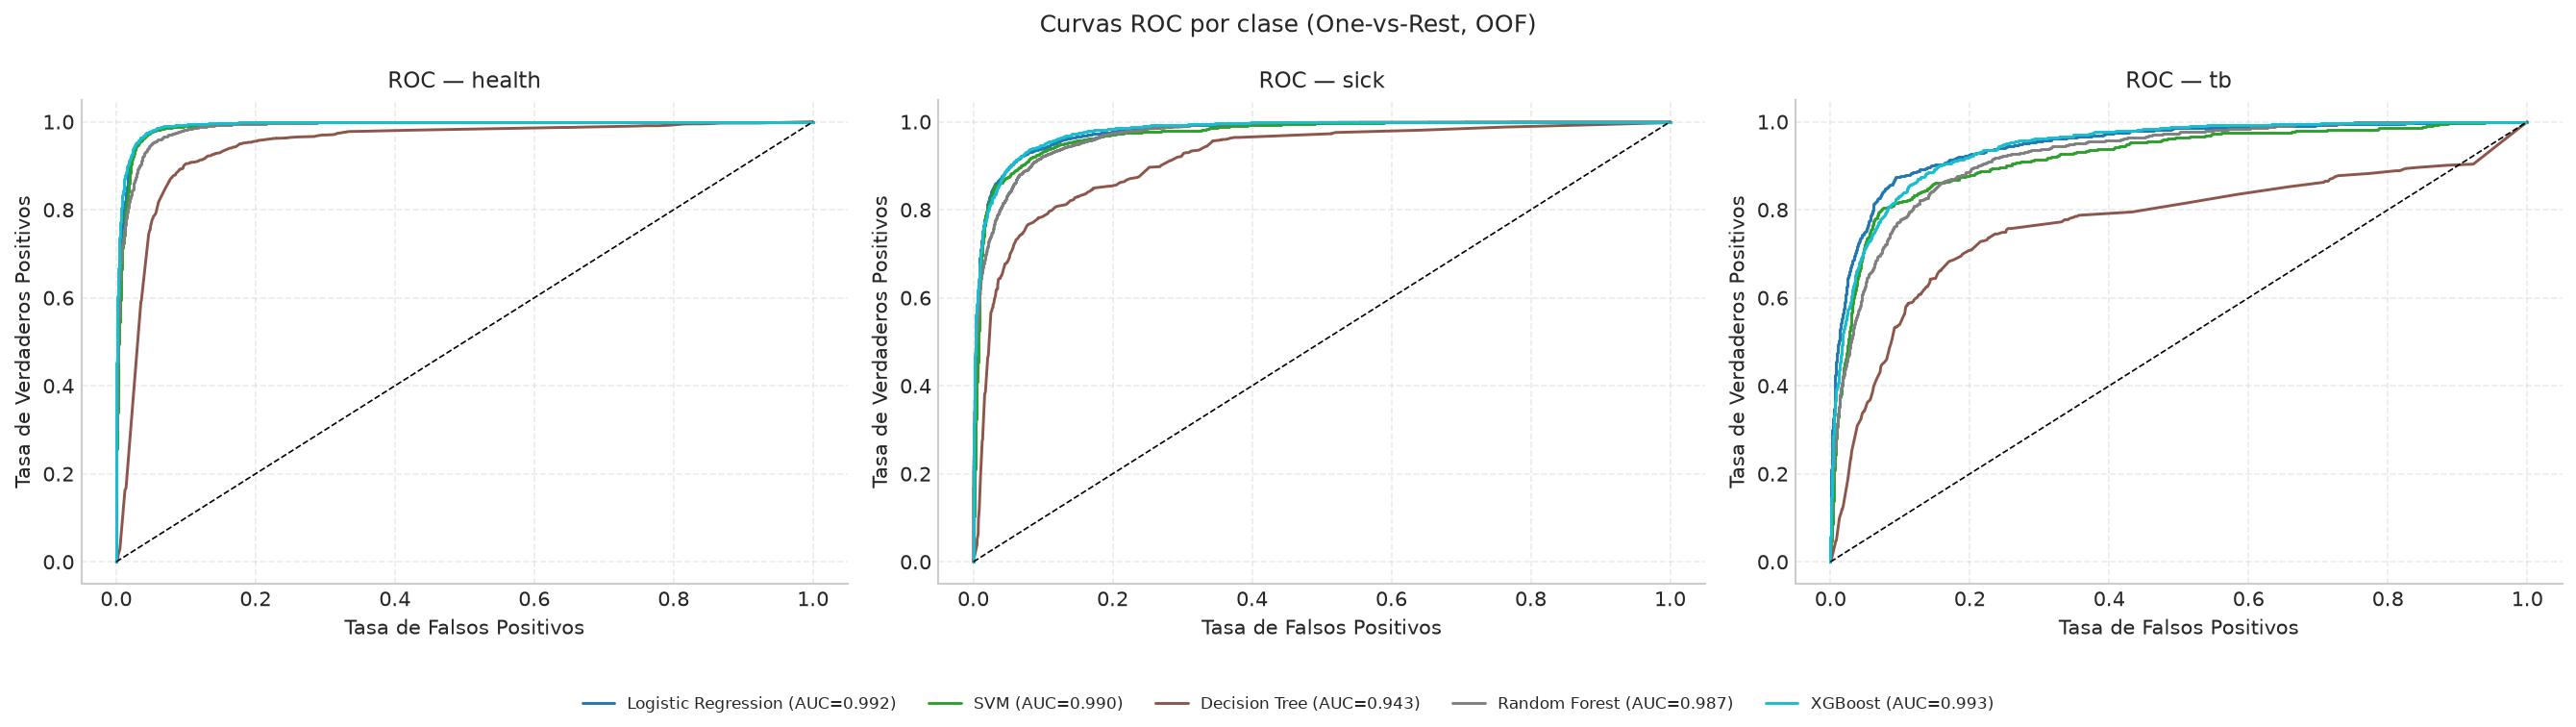

In [24]:
# Curvas ROC One-vs-Rest para las 8256 predicciones OOF.

colores = plt.cm.tab10(np.linspace(0, 1, len(MODELOS)))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (k, clase) in zip(axes, enumerate(CLASS_NAMES)):
    for color, nombre in zip(colores, MODELOS):
        y_bin = (y_true == k).astype(int)
        fpr, tpr, _ = roc_curve(y_bin, puntuaciones[nombre][:, k])
        ax.plot(fpr, tpr, color=color, lw=1.4,
                label=f'{nombre} (AUC={auc(fpr, tpr):.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax.set_xlabel('Tasa de Falsos Positivos', fontsize=10)
    ax.set_ylabel('Tasa de Verdaderos Positivos', fontsize=10)
    ax.set_title(f'ROC — {clase}', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.4)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, fontsize=8, frameon=False)
fig.suptitle('Curvas ROC por clase (One-vs-Rest, OOF)', fontsize=12)
fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.savefig(REPORTS_DIR / '09_roc_por_clase.png', dpi=300, bbox_inches='tight')
plt.show()


## 5. Curvas Average Precision (tb)


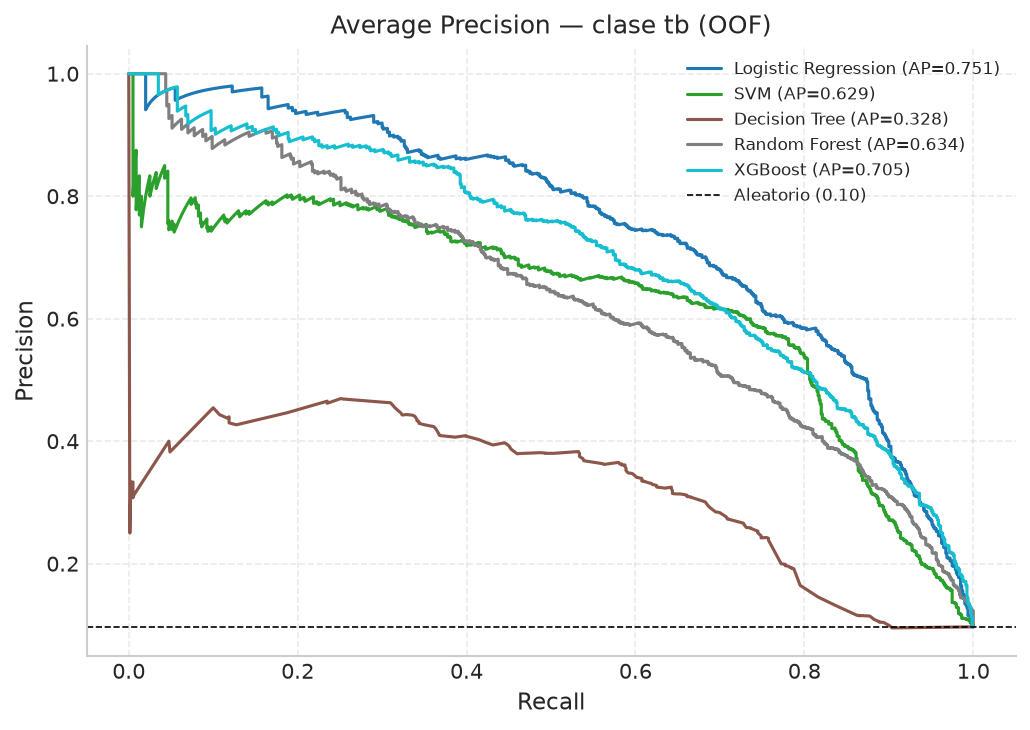

In [25]:
# AP (average precision) es más informativa que ROC-AUC con clase positiva minoritaria.
# Es AP, no el área trapezoidal de la curva PR.
# Referencia: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html

fig, ax = plt.subplots(figsize=(7, 5))
y_tb = (y_true == 2).astype(int)

for color, nombre in zip(colores, MODELOS):
    precision, recall, _ = precision_recall_curve(y_tb, puntuaciones[nombre][:, 2])
    ap = average_precision_score(y_tb, puntuaciones[nombre][:, 2])
    ax.plot(recall, precision, color=color, lw=1.5,
            label=f'{nombre} (AP={ap:.3f})')

ax.axhline(y_tb.mean(), color='k', linestyle='--', lw=0.8,
           label=f'Aleatorio ({y_tb.mean():.2f})')
ax.set_xlabel('Recall', fontsize=11)
ax.set_ylabel('Precision', fontsize=11)
ax.set_title('Average Precision — clase tb (OOF)', fontsize=12)
ax.legend(fontsize=8)
ax.grid(True, linestyle='--', alpha=0.4)
fig.tight_layout()
fig.savefig(REPORTS_DIR / '09_ap_tb.png', dpi=300, bbox_inches='tight')
plt.show()


## 6. Matrices de confusión y errores


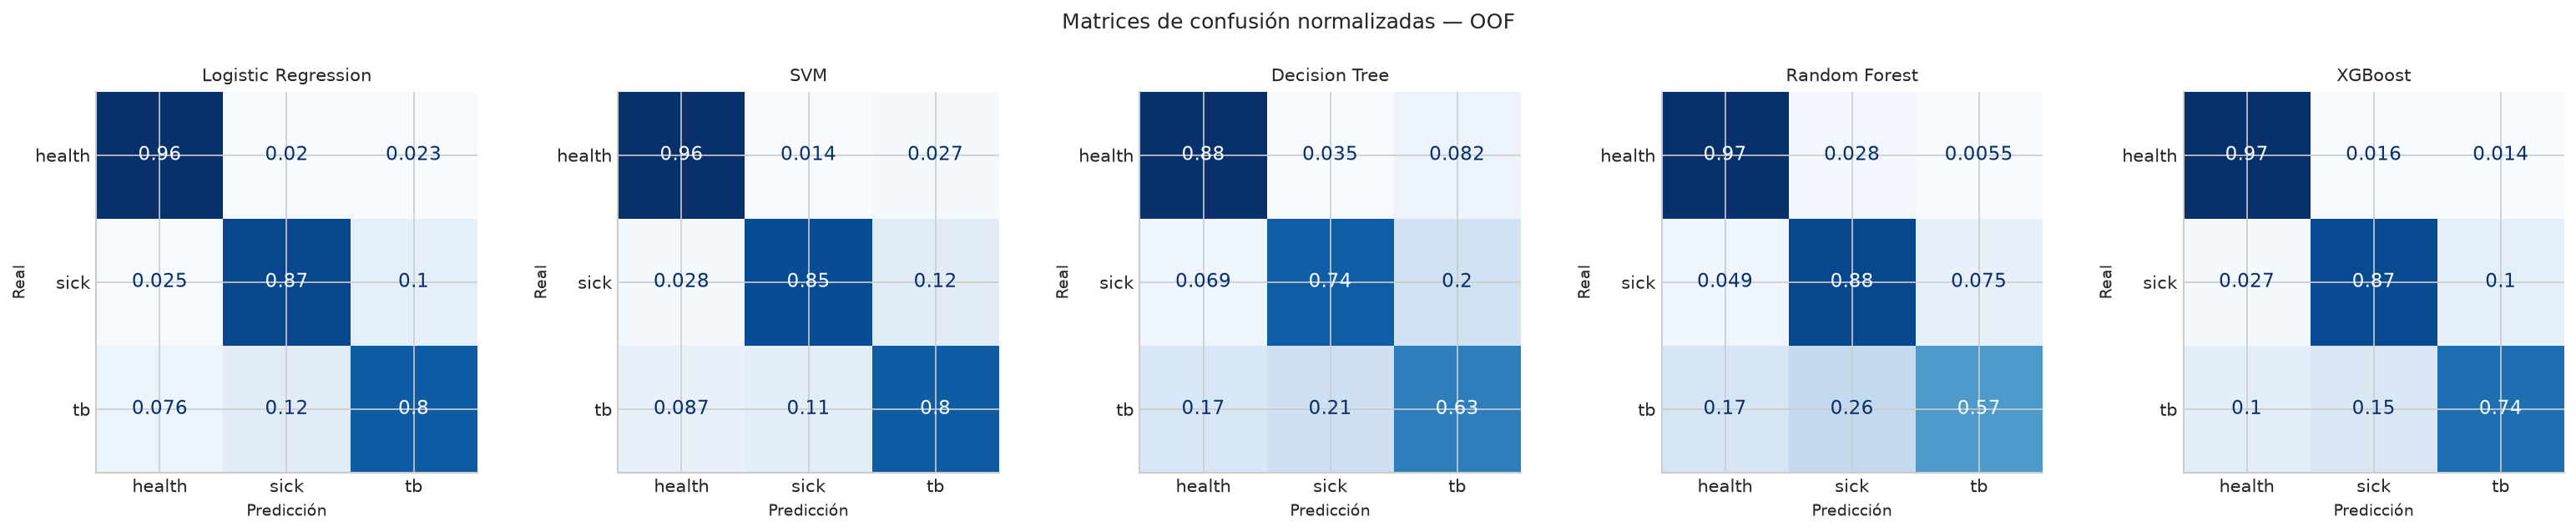

Confusiones principales (conteos absolutos):
Modelo                  tb->sick  sick->tb  tb->health  health->tb
Logistic Regression         100      379          61         86
SVM                          91      439          70        104
Decision Tree               166      716         132        310
Random Forest               205      275         136         21
XGBoost                     124      374          84         54


In [26]:
# Matrices normalizadas por fila (recall por clase) y conteos de confusiones tb/sick.

fig, axes = plt.subplots(1, len(MODELOS), figsize=(4.2 * len(MODELOS), 4))
for ax, nombre in zip(axes, MODELOS):
    ConfusionMatrixDisplay.from_predictions(
        y_true, predicciones[nombre],
        display_labels=CLASS_NAMES,
        normalize='true', colorbar=False, cmap='Blues', ax=ax,
    )
    ax.set_title(nombre, fontsize=10)
    ax.set_xlabel('Predicción', fontsize=9)
    ax.set_ylabel('Real', fontsize=9)

fig.suptitle('Matrices de confusión normalizadas — OOF', fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(REPORTS_DIR / '09_matrices_confusion.png', dpi=300, bbox_inches='tight')
plt.show()

print('Confusiones principales (conteos absolutos):')
print(f'{"Modelo":22s}  tb->sick  sick->tb  tb->health  health->tb')
for nombre in MODELOS:
    cm = confusion_matrix(y_true, predicciones[nombre])
    print(f'{nombre:22s}  {cm[2, 1]:7d}  {cm[1, 2]:7d}  {cm[2, 0]:10d}  {cm[0, 2]:9d}')


## 7. Comparación estadística

> Los p-valores de McNemar se corrigen con **Holm**. Se reportan el test global y uno
> restringido a los casos de `tb`.


In [27]:
# Bootstrap estratificado para balanced accuracy y recall de tb; McNemar global y de tb.

def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    clases = np.unique(y_true)
    idx = {c: np.where(y_true == c)[0] for c in clases}
    valores = []
    for _ in range(n_boot):
        muestra = np.concatenate([
            rng.choice(idx[c], size=len(idx[c]), replace=True) for c in clases
        ])
        valores.append(metric_fn(y_true[muestra], y_pred[muestra]))
    return np.percentile(valores, [2.5, 97.5])


filas = []
for nombre in MODELOS:
    y_pred = predicciones[nombre]
    bacc_lo, bacc_hi = bootstrap_ci(y_true, y_pred, balanced_accuracy_score)
    rec_lo, rec_hi = bootstrap_ci(
        y_true, y_pred,
        lambda yt, yp: recall_score(yt, yp, labels=[2], average=None)[0],
    )
    filas.append({
        'Modelo': nombre,
        'BalAcc': balanced_accuracy_score(y_true, y_pred),
        'BalAcc IC95 inf': bacc_lo,
        'BalAcc IC95 sup': bacc_hi,
        'Recall tb': recall_score(y_true, y_pred, labels=[2], average=None)[0],
        'Recall tb IC95 inf': rec_lo,
        'Recall tb IC95 sup': rec_hi,
    })

intervalos = pd.DataFrame(filas).sort_values('BalAcc', ascending=False)
print('Intervalos de confianza al 95 % (bootstrap estratificado):')
print(intervalos.round(4).to_string(index=False))


def mcnemar(y_true, pred_a, pred_b):
    a_ok = pred_a == y_true
    b_ok = pred_b == y_true
    n01 = np.sum(a_ok & ~b_ok)
    n10 = np.sum(~a_ok & b_ok)
    if n01 + n10 == 0:
        return np.nan, np.nan
    stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
    return stat, chi2.sf(stat, 1)


def tabla_mcnemar(y_eval, preds):
    nombres = list(preds)
    pares = []
    for i in range(len(nombres)):
        for j in range(i + 1, len(nombres)):
            _, p = mcnemar(y_eval, preds[nombres[i]], preds[nombres[j]])
            if p != p:
                p = 1.0
            pares.append({'Modelo A': nombres[i], 'Modelo B': nombres[j], 'p': p})
    m = len(pares)
    orden = sorted(range(m), key=lambda k: pares[k]['p'])
    anterior = 0.0
    for rango, k in enumerate(orden):
        ajustado = min(1.0, (m - rango) * pares[k]['p'])
        ajustado = max(ajustado, anterior)
        anterior = ajustado
        pares[k]['p Holm'] = ajustado
    return pares


pares = tabla_mcnemar(y_true, predicciones)
print()
print('McNemar global (OOF; p crudo y Holm):')
print(f'{"Modelo A":22s} {"Modelo B":22s} {"p":>8s} {"p Holm":>8s} {"significativo":>14s}')
for par in sorted(pares, key=lambda d: d['p']):
    sig = 'sí' if par['p Holm'] < 0.05 else 'no'
    print(f'{par["Modelo A"]:22s} {par["Modelo B"]:22s} '
          f'{par["p"]:8.4f} {par["p Holm"]:8.4f} {sig:>14s}')

mask_tb = y_true == 2
pares_tb = tabla_mcnemar(y_true[mask_tb], {n: p[mask_tb] for n, p in predicciones.items()})
print()
print('McNemar restringido a tb (OOF; p crudo y Holm):')
print(f'{"Modelo A":22s} {"Modelo B":22s} {"p":>8s} {"p Holm":>8s} {"significativo":>14s}')
for par in sorted(pares_tb, key=lambda d: d['p']):
    sig = 'sí' if par['p Holm'] < 0.05 else 'no'
    print(f'{par["Modelo A"]:22s} {par["Modelo B"]:22s} '
          f'{par["p"]:8.4f} {par["p Holm"]:8.4f} {sig:>14s}')


Intervalos de confianza al 95 % (bootstrap estratificado):
             Modelo  BalAcc  BalAcc IC95 inf  BalAcc IC95 sup  Recall tb  Recall tb IC95 inf  Recall tb IC95 sup
Logistic Regression  0.8757           0.8648           0.8857     0.7988              0.7700              0.8262
                SVM  0.8698           0.8594           0.8796     0.7988              0.7712              0.8250
            XGBoost  0.8601           0.8488           0.8712     0.7400              0.7087              0.7700
      Random Forest  0.8053           0.7943           0.8172     0.5738              0.5412              0.6063
      Decision Tree  0.7487           0.7366           0.7609     0.6275              0.5938              0.6587

McNemar global (OOF; p crudo y Holm):
Modelo A               Modelo B                      p   p Holm  significativo
Decision Tree          XGBoost                  0.0000   0.0000             sí
Logistic Regression    Decision Tree            0.0000   0.0000   

## 8. Calibración de probabilidades (tb)


Brier score para tb (menor es mejor):
             Modelo  Brier tb
            XGBoost    0.0541
Logistic Regression    0.0556
      Random Forest    0.0592
      Decision Tree    0.1097


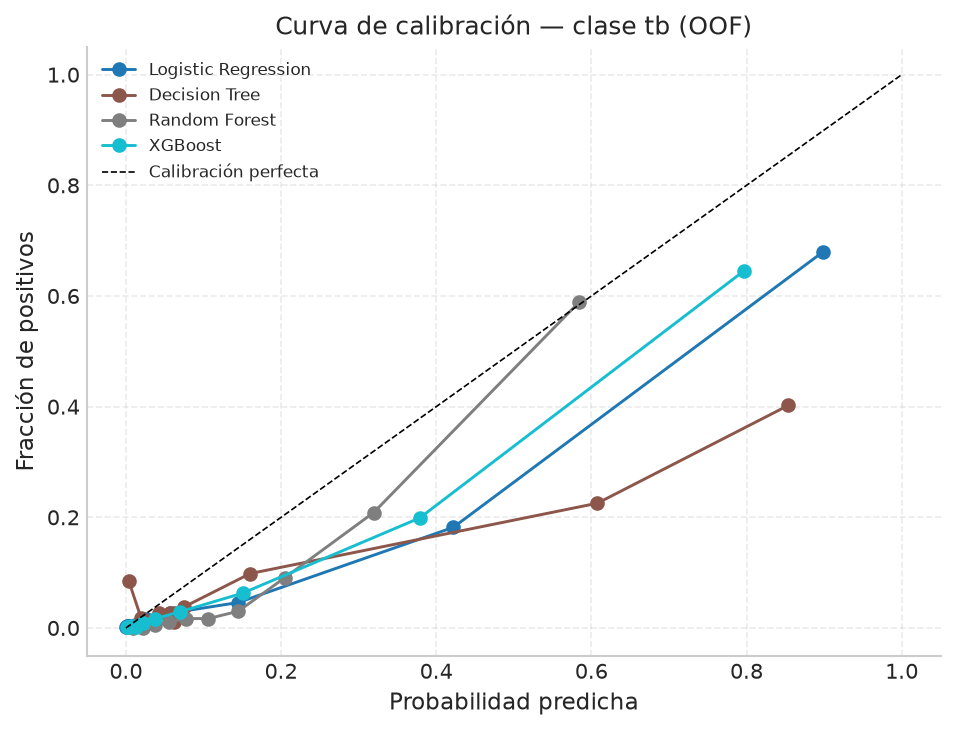

In [28]:
# Brier score y curva de calibración para tb sobre los scores OOF.
# Solo modelos con predict_proba: LR, DT, RF y XGBoost. SVM no expone probabilidades.

modelos_proba = [n for n in MODELOS if n != 'SVM']
y_tb = (y_true == 2).astype(int)

filas_cal = []
for nombre in modelos_proba:
    prob_tb = puntuaciones[nombre][:, 2]
    filas_cal.append({'Modelo': nombre, 'Brier tb': brier_score_loss(y_tb, prob_tb)})

calibracion = pd.DataFrame(filas_cal).sort_values('Brier tb')
print('Brier score para tb (menor es mejor):')
print(calibracion.round(4).to_string(index=False))
calibracion.to_csv(DATA_DIR / '09_calibracion.csv', index=False)

fig, ax = plt.subplots(figsize=(6.5, 5))
colores_modelo = dict(zip(MODELOS, colores))
for nombre in modelos_proba:
    prob_true, prob_pred = calibration_curve(
        y_tb, puntuaciones[nombre][:, 2], n_bins=10, strategy='quantile',
    )
    ax.plot(prob_pred, prob_true, 'o-', color=colores_modelo[nombre], lw=1.4, label=nombre)

ax.plot([0, 1], [0, 1], 'k--', lw=0.8, label='Calibración perfecta')
ax.set_xlabel('Probabilidad predicha', fontsize=11)
ax.set_ylabel('Fracción de positivos', fontsize=11)
ax.set_title('Curva de calibración — clase tb (OOF)', fontsize=12)
ax.legend(fontsize=8)
ax.grid(True, linestyle='--', alpha=0.4)
fig.tight_layout()
fig.savefig(REPORTS_DIR / '09_calibracion_tb.png', dpi=300, bbox_inches='tight')
plt.show()


## 9. Recomendación final

La selección del modelo se hizo en el notebook 08 con la **CV out-of-fold**. Aquí se
reporta el desempeño de esos modelos sobre las mismas 8256 imágenes; el ranking es
descriptivo y no se usa para reseleccionar.


In [29]:
# El modelo recomendado es el seleccionado por la CV OOF del 08.
ranking_oof = resultados_globales.sort_values(
    ['Balanced Acc', 'Recall tb', 'AP tb'], ascending=False,
).reset_index(drop=True)

seleccionado_cv = manifest.get('seleccionado_cv')
mejor_oof = ranking_oof.iloc[0]['Modelo']
fila_sel = ranking_oof[ranking_oof['Modelo'] == seleccionado_cv].iloc[0]

print('Ranking OOF (descriptivo):')
print(ranking_oof[['Modelo', 'Balanced Acc', 'Recall tb', 'AP tb']].round(4).to_string(index=False))
print()
print(f'Modelo recomendado (seleccionado por CV OOF en 08): {seleccionado_cv}')
print(f'  BalAcc OOF : {fila_sel["Balanced Acc"]:.4f}')
print(f'  Recall tb  : {fila_sel["Recall tb"]:.4f}')
print(f'  AP tb      : {fila_sel["AP tb"]:.4f}')
print()
print(f'Mejor OOF (descriptivo): {mejor_oof}')


def _p_holm(tabla, a, b):
    par = next((p for p in tabla if {p['Modelo A'], p['Modelo B']} == {a, b}), None)
    return None if par is None else par['p Holm']


p_global = _p_holm(pares, mejor_oof, seleccionado_cv)
p_tb = _p_holm(pares_tb, mejor_oof, seleccionado_cv)
if mejor_oof != seleccionado_cv:
    print()
    print(f'Nota: {mejor_oof} no fue el elegido por CV. No se cambia la selección.')
if p_global is not None:
    print(f'McNemar global {mejor_oof} vs {seleccionado_cv}: p Holm={p_global:.4f}')
if p_tb is not None:
    print(f'McNemar en tb  {mejor_oof} vs {seleccionado_cv}: p Holm={p_tb:.4f}')

recomendacion = {
    'politica': 'seleccion_por_cv_oof; sin hold-out',
    'modelo_recomendado': seleccionado_cv,
    'mejor_oof': mejor_oof,
    'balanced_accuracy_oof': float(fila_sel['Balanced Acc']),
    'recall_tb_oof': float(fila_sel['Recall tb']),
    'ap_tb_oof': float(fila_sel['AP tb']),
    'mejor_oof_balanced_accuracy': float(ranking_oof.iloc[0]['Balanced Acc']),
    'mcnemar_global_holm_mejor_vs_recomendado': None if p_global is None else float(p_global),
    'mcnemar_tb_holm_mejor_vs_recomendado': None if p_tb is None else float(p_tb),
}
with open(DATA_DIR / '09_recomendacion.json', 'w', encoding='utf-8') as f:
    json.dump(recomendacion, f, ensure_ascii=False, indent=2)

print()
print(f'Recomendación guardada en: {(DATA_DIR / "09_recomendacion.json").resolve()}')


Ranking OOF (descriptivo):
             Modelo  Balanced Acc  Recall tb  AP tb
Logistic Regression        0.8757     0.7988 0.7509
                SVM        0.8698     0.7988 0.6286
            XGBoost        0.8601     0.7400 0.7047
      Random Forest        0.8053     0.5738 0.6341
      Decision Tree        0.7487     0.6275 0.3281

Modelo recomendado (seleccionado por CV OOF en 08): Logistic Regression
  BalAcc OOF : 0.8757
  Recall tb  : 0.7987
  AP tb      : 0.7509

Mejor OOF (descriptivo): Logistic Regression

Recomendación guardada en: C:\Users\estra\Desktop\Tuberculosis\cad-tbx11k\data\09_recomendacion.json


## 10. Estimación OOF del procedimiento completo

Las métricas por modelo son descriptivas. La estimación menos optimista del **procedimiento
completo** (selector + hiperparámetros + selección de modelo) se calculó en el notebook 08:
en cada fold externo se eligió el modelo con mejor score interno y se evaluó en el fold
externo. Se reporta aquí como referencia.


In [30]:
# Estimación OOF del procedimiento completo (sin reutilizar el ranking para reseleccionar).
proc_path = DATA_DIR / '08_procedimiento.json'
if proc_path.exists():
    with open(proc_path, encoding='utf-8') as f:
        proc = json.load(f)
    print('Modelo seleccionado en cada fold externo:', proc['selected_per_fold'])
    print()
    print('Métricas OOF del procedimiento completo:')
    for k, v in proc['metricas_oof'].items():
        if v is None:
            print(f'  {k}: no comparable')
        else:
            print(f'  {k}: {v:.4f}')
else:
    print('No se encontró 08_procedimiento.json.')


Modelo seleccionado en cada fold externo: {'1': 'Logistic Regression', '2': 'Logistic Regression', '3': 'Logistic Regression', '4': 'Logistic Regression', '5': 'Logistic Regression'}

Métricas OOF del procedimiento completo:
  Balanced Acc: 0.8757
  F1 macro: 0.8458
  Recall tb: 0.7987
  AUC-ROC macro: no comparable
  AP tb: no comparable


## 11. Robustez: duplicados perceptuales y CV agrupada

Se recalcula el dHash 8×8 de cada imagen y se cuantifican hashes repetidos, pares,
conflictos de etiqueta y pares que cruzan folds. Después se compara la CV estratificada
habitual con una **CV agrupada por dHash** usando las mismas 300 features y los mismos
parámetros del notebook 08.

Si la CV agrupada baja, parte del rendimiento venía de casi-copias entre folds; si se
mantiene, el agrupamiento no es la causa principal.


In [31]:
# dHash 8x8 y CV agrupada.
# Referencias:
#   dHash: https://www.hackerfactor.com/blog/index.php?/archives/529-Kind-of-Like-That.html
#   StratifiedGroupKFold: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html

import cv2
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, recall_score, average_precision_score,
)

meta = pd.read_csv(DATA_DIR / 'full_meta.csv')
y_full = np.load(DATA_DIR / 'y_full.npy')
if len(meta) != len(y_full):
    raise ValueError('full_meta.csv y y_full.npy no coinciden en longitud.')


def dhash_8x8(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.resize(img, (9, 8), interpolation=cv2.INTER_AREA)
    diff = img[:, 1:] > img[:, :-1]
    return int(''.join('1' if x else '0' for x in diff.flatten()), 2)


hashes = meta['image_path'].map(dhash_8x8)
if hashes.isna().any():
    raise ValueError('Hay imágenes que no se pudieron leer para dHash.')

meta_hash = meta.assign(dhash=hashes)
meta_hash.to_csv(DATA_DIR / '09_dhash.csv', index=False)

cuentas = hashes.value_counts()
dup = cuentas[cuentas > 1]
n_dup_images = int(dup.sum())
n_pairs = int(sum(n * (n - 1) // 2 for n in dup))
conflictos = meta_hash.groupby('dhash')['label'].nunique().gt(1)

cv_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold = np.zeros(len(meta_hash), dtype=int)
for f, (_, va) in enumerate(cv_fold.split(np.zeros(len(meta_hash)), meta_hash['label']), start=1):
    fold[va] = f
meta_hash['fold'] = fold

pares_cruzados = 0
grupos_cruzados = 0
for _, grupo in meta_hash[meta_hash['dhash'].isin(dup.index)].groupby('dhash'):
    por_fold = grupo['fold'].value_counts()
    if len(por_fold) > 1:
        grupos_cruzados += 1
        total = len(grupo) * (len(grupo) - 1) // 2
        dentro = sum(n * (n - 1) // 2 for n in por_fold)
        pares_cruzados += total - dentro

print(f'Imágenes con dHash repetido: {n_dup_images} ({100*n_dup_images/len(meta):.1f} %)')
print(f'Hashes repetidos: {len(dup)} | Pares: {n_pairs}')
print(f'Grupos con etiquetas distintas: {int(conflictos.sum())}')
print(f'Grupos en varios folds: {grupos_cruzados} | Pares que cruzan folds: {pares_cruzados}')

resumen = {
    'imagenes': int(len(meta_hash)),
    'hashes_repetidos': int(len(dup)),
    'imagenes_con_hash_repetido': n_dup_images,
    'pares_mismo_hash': n_pairs,
    'grupos_con_etiquetas_distintas': int(conflictos.sum()),
    'grupos_en_varios_folds': grupos_cruzados,
    'pares_que_cruzan_folds': pares_cruzados,
}
with open(DATA_DIR / '09_dhash_resumen.json', 'w', encoding='utf-8') as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)

# CV referencia vs agrupada con las 300 features del 06.
feat_cols = model_feature_columns(
    pd.read_csv(DATA_DIR / 'features_tbx11k.csv', nrows=0)
)
with open(DATA_DIR / '06_selected_feature_names.json', encoding='utf-8') as f:
    sel_names = json.load(f)
X_sel = np.load(DATA_DIR / 'X_full.npy')[:, [feat_cols.index(n) for n in sel_names]]

with open(DATA_DIR / '08_mejores_params.json', encoding='utf-8') as f:
    params_08 = json.load(f)
LR_C = params_08['Logistic Regression']['clf__C']
SVM_C = params_08['SVM']['clf__C']


def metricas_cv(y_true, y_pred, y_score):
    return {
        'BalAcc': balanced_accuracy_score(y_true, y_pred),
        'F1 macro': f1_score(y_true, y_pred, average='macro'),
        'Recall tb': recall_score(y_true, y_pred, labels=[2], average=None)[0],
        'AP tb': average_precision_score((y_true == 2).astype(int), y_score[:, 2]),
    }


def evaluar_cv(splitter, X, y, groups=None):
    modelos = {
        'Logistic Regression': LogisticRegression(
            C=LR_C, class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE,
        ),
        'SVM': SVC(
            kernel='linear', C=SVM_C, class_weight='balanced',
            cache_size=500, random_state=RANDOM_STATE,
        ),
    }
    salida = {}
    for nombre, base in modelos.items():
        oof_pred = np.full(len(y), -1, dtype=int)
        oof_score = np.full((len(y), len(CLASS_NAMES)), np.nan)
        iterador = (splitter.split(X, y, groups) if groups is not None
                    else splitter.split(X, y))
        for tr, va in iterador:
            scaler = StandardScaler().fit(X[tr])
            X_tr = scaler.transform(X[tr])
            X_va = scaler.transform(X[va])
            clf = clone(base).fit(X_tr, y[tr])
            oof_pred[va] = clf.predict(X_va)
            oof_score[va] = (clf.predict_proba(X_va) if hasattr(clf, 'predict_proba')
                             else clf.decision_function(X_va))
        salida[nombre] = metricas_cv(y, oof_pred, oof_score)
    return salida


referencia = evaluar_cv(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    X_sel, y_full,
)
agrupada = evaluar_cv(
    StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    X_sel, y_full, groups=hashes.to_numpy(),
)

filas = []
for nombre in referencia:
    filas.append({'Modelo': nombre, 'CV': 'estratificada', **referencia[nombre]})
    filas.append({'Modelo': nombre, 'CV': 'agrupada dHash', **agrupada[nombre]})
tabla_cv = pd.DataFrame(filas)
tabla_cv.to_csv(DATA_DIR / '09_robustez_cv.csv', index=False)
print()
print(tabla_cv.round(4).to_string(index=False))
print()
for nombre in referencia:
    print(f'{nombre:22s} ΔBalAcc agrupada - referencia: '
          f'{agrupada[nombre]["BalAcc"] - referencia[nombre]["BalAcc"]:+.4f}')


Imágenes con dHash repetido: 1546 (18.7 %)
Hashes repetidos: 477 | Pares: 5643
Grupos con etiquetas distintas: 141
Grupos en varios folds: 415 | Pares que cruzan folds: 4483

             Modelo             CV  BalAcc  F1 macro  Recall tb  AP tb
Logistic Regression  estratificada  0.8712    0.8432     0.7850 0.7598
Logistic Regression agrupada dHash  0.8734    0.8423     0.8000 0.7615
                SVM  estratificada  0.8665    0.8330     0.7900 0.6289
                SVM agrupada dHash  0.8681    0.8350     0.7912 0.6266

Logistic Regression    ΔBalAcc agrupada - referencia: +0.0022
SVM                    ΔBalAcc agrupada - referencia: +0.0016


## 12. Baseline de solo fondo/borde

Se extraen features compactas de cuatro esquinas y una franja inferior de la imagen
preprocesada. Si un modelo entrenado solo con esas zonas predice bien la clase, hay
evidencia de atajo por contexto o adquisición; si queda cerca de 0.333, no.


In [32]:
# Baseline de fondo con las mismas condiciones que el pulmón:
# solo GLCM y LBP, con la intensidad normalizada dentro de la máscara de fondo.
from src.features import extract_background_texture

N_POR_CLASE = 1000
rng = np.random.RandomState(RANDOM_STATE)
idx_bg = []
for clase in np.unique(y_full):
    idx_clase = np.where(y_full == clase)[0]
    idx_bg.extend(
        rng.choice(idx_clase, size=min(N_POR_CLASE, len(idx_clase)), replace=False)
    )
idx_bg = np.array(idx_bg)

filas_bg, y_bg, groups_bg = [], [], []
for idx in idx_bg:
    fila = extract_background_texture(meta.loc[idx, 'image_path'])
    if fila is None:
        continue
    filas_bg.append(fila)
    y_bg.append(y_full[idx])
    groups_bg.append(hashes.iloc[idx])

X_bg = pd.DataFrame(filas_bg).fillna(0)
y_bg = np.asarray(y_bg)
groups_bg = np.asarray(groups_bg)

print(f'Subconjunto de fondo: {X_bg.shape}')
resultado_bg = evaluar_cv(
    StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    X_bg.values, y_bg, groups=groups_bg,
)
tabla_bg = pd.DataFrame([
    {'Modelo': nombre, **valores} for nombre, valores in resultado_bg.items()
])
tabla_bg.to_csv(DATA_DIR / '09_robustez_fondo.csv', index=False)
print()
print('Baseline de fondo (GLCM/LBP normalizados, CV agrupada):')
print(tabla_bg.round(4).to_string(index=False))
print()
print('Azar para 3 clases: balanced accuracy ≈ 0.333')


Subconjunto de fondo: (2800, 36)

Baseline de fondo (GLCM/LBP normalizados, CV agrupada):
             Modelo  BalAcc  F1 macro  Recall tb  AP tb
Logistic Regression  0.8630    0.8623     0.8000 0.8533
                SVM  0.8525    0.8512     0.7925 0.7848

Azar para 3 clases: balanced accuracy ≈ 0.333


## 13. Baseline de solo forma de la máscara

Se usan únicamente área, balance izquierda-derecha, caja, extensión, centroide
y momentos de Hu de la máscara. Si este baseline predice bien la clase, la
forma del campo pulmonar está filtrando información de fuente o adquisición.


In [33]:
from src.preprocessing import segment_image

N_POR_CLASE_FORMA = 1000
rng_forma = np.random.RandomState(RANDOM_STATE)
idx_forma = []
for clase in np.unique(y_full):
    idx_clase = np.where(y_full == clase)[0]
    idx_forma.extend(
        rng_forma.choice(
            idx_clase,
            size=min(N_POR_CLASE_FORMA, len(idx_clase)),
            replace=False,
        )
    )
idx_forma = np.array(idx_forma)

filas_forma, y_forma, groups_forma = [], [], []
for idx in idx_forma:
    mask, q = segment_image(meta.loc[idx, 'image_path'])
    if mask is None or not mask.any():
        continue
    ys, xs = np.where(mask)
    h, w = mask.shape
    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int(ys.min()), int(ys.max()) + 1
    area = int(mask.sum())
    bbox = max((x1 - x0) * (y1 - y0), 1)
    hu = cv2.HuMoments(cv2.moments(mask.astype(np.uint8))).flatten()
    hu = np.sign(hu) * np.log1p(np.abs(hu))
    filas_forma.append({
        'area_fraction': area / (h * w),
        'lr_balance': q.lr_balance,
        'bbox_w': (x1 - x0) / w,
        'bbox_h': (y1 - y0) / h,
        'extent': area / bbox,
        'centroid_x': float(xs.mean()) / w,
        'centroid_y': float(ys.mean()) / h,
        **{f'hu_{i}': float(hu[i]) for i in range(7)},
    })
    y_forma.append(y_full[idx])
    groups_forma.append(hashes.iloc[idx])

X_forma = pd.DataFrame(filas_forma).fillna(0)
y_forma = np.asarray(y_forma)
groups_forma = np.asarray(groups_forma)

resultado_forma = evaluar_cv(
    StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    X_forma.values, y_forma, groups=groups_forma,
)
tabla_forma = pd.DataFrame([
    {'Modelo': nombre, **valores} for nombre, valores in resultado_forma.items()
])
tabla_forma.to_csv(DATA_DIR / '09_robustez_forma.csv', index=False)
print('Baseline de solo forma (CV agrupada):')
print(tabla_forma.round(4).to_string(index=False))


Baseline de solo forma (CV agrupada):
             Modelo  BalAcc  F1 macro  Recall tb  AP tb
Logistic Regression  0.6957    0.6955      0.565 0.5893
                SVM  0.6937    0.6934      0.570 0.5334


## 14. Auditoría de textura, borde y alta frecuencia

Compara textura completa, textura del interior erosionado, textura tras
desenfoque, textura tras reducir resolución y forma sola. Si la textura
interna se mantiene, hay señal anatómica; si se cae con el desenfoque, la
señal era de alta frecuencia/adquisición.


In [34]:
from src.features import extract_interior_texture, extract_texture_variant
from src.preprocessing import segment_image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

N_DIAG = 300
rng_diag = np.random.RandomState(RANDOM_STATE)
idx_diag = []
for clase in np.unique(y_full):
    idx_clase = np.where(y_full == clase)[0]
    idx_diag.extend(
        rng_diag.choice(idx_clase, size=min(N_DIAG, len(idx_clase)), replace=False)
    )
idx_diag = np.array(idx_diag)

filas = {
    'textura_full': [], 'textura_interior': [],
    'textura_blur': [], 'textura_downsample': [], 'forma': [],
}
y_diag, groups_diag = [], []

for idx in idx_diag:
    path = meta.loc[idx, 'image_path']
    full = extract_texture_variant(path, 'full')
    inner = extract_interior_texture(path)
    blur = extract_texture_variant(path, 'blur')
    down = extract_texture_variant(path, 'downsample')
    mask, q = segment_image(path)
    if full is None or inner is None or blur is None or down is None or mask is None:
        continue
    filas['textura_full'].append(full)
    filas['textura_interior'].append(inner)
    filas['textura_blur'].append(blur)
    filas['textura_downsample'].append(down)

    ys, xs = np.where(mask)
    h, w = mask.shape
    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int(ys.min()), int(ys.max()) + 1
    area = int(mask.sum())
    bbox = max((x1 - x0) * (y1 - y0), 1)
    hu = cv2.HuMoments(cv2.moments(mask.astype(np.uint8))).flatten()
    hu = np.sign(hu) * np.log1p(np.abs(hu))
    filas['forma'].append({
        'area_fraction': area / (h * w),
        'lr_balance': q.lr_balance,
        'bbox_w': (x1 - x0) / w,
        'bbox_h': (y1 - y0) / h,
        'extent': area / bbox,
        'centroid_x': float(xs.mean()) / w,
        'centroid_y': float(ys.mean()) / h,
        **{f'hu_{i}': float(hu[i]) for i in range(7)},
    })
    y_diag.append(y_full[idx])
    groups_diag.append(hashes.iloc[idx])

y_diag = np.asarray(y_diag)
groups_diag = np.asarray(groups_diag)
filas['textura_interior+forma'] = [
    {**a, **b} for a, b in zip(filas['textura_interior'], filas['forma'])
]

filas_resultado = []
for nombre, registros in filas.items():
    X = pd.DataFrame(registros).fillna(0)
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    bacc, f1 = [], []
    for tr, va in cv.split(X, y_diag, groups=groups_diag):
        scaler = StandardScaler()
        Xtr = scaler.fit_transform(X.values[tr])
        Xva = scaler.transform(X.values[va])
        clf = LogisticRegression(
            class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE
        )
        clf.fit(Xtr, y_diag[tr])
        pred = clf.predict(Xva)
        bacc.append(balanced_accuracy_score(y_diag[va], pred))
        f1.append(f1_score(y_diag[va], pred, average='macro'))
    filas_resultado.append({
        'conjunto': nombre,
        'n_features': X.shape[1],
        'Balanced Acc': float(np.mean(bacc)),
        'F1 macro': float(np.mean(f1)),
    }) 

tabla_auditoria = pd.DataFrame(filas_resultado).sort_values(
    'Balanced Acc', ascending=False
)
tabla_auditoria.to_csv(DATA_DIR / '09_auditoria_textura.csv', index=False)
print(tabla_auditoria.round(4).to_string(index=False))


              conjunto  n_features  Balanced Acc  F1 macro
textura_interior+forma          82        0.8378    0.8372
          textura_full          68        0.8323    0.8315
      textura_interior          68        0.8290    0.8279
    textura_downsample          68        0.8034    0.8022
          textura_blur          68        0.7900    0.7890
                 forma          14        0.7024    0.7000


## 15. Tareas por pares

Se comparan TB vs sick, TB vs health y health vs sick usando el modelo
pulmonar y el baseline de fondo. Si TB vs sick funciona sin fondo ni
intensidad, la señal pulmonar gana credibilidad.


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, f1_score, recall_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

X_pulmon = np.load(DATA_DIR / 'X_full.npy')
y_pulmon = np.load(DATA_DIR / 'y_full.npy')


def _evaluar_par(X, y, par, nombre_par):
    mask = np.isin(y, par)
    Xp, yp = X[mask], y[mask]
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    bacc, f1, rec_tb, ap_tb = [], [], [], []
    for tr, va in cv.split(Xp, yp):
        scaler = StandardScaler()
        Xtr = scaler.fit_transform(Xp[tr])
        Xva = scaler.transform(Xp[va])
        clf = LogisticRegression(
            class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE
        )
        clf.fit(Xtr, yp[tr])
        pred = clf.predict(Xva)
        prob = clf.predict_proba(Xva)
        bacc.append(balanced_accuracy_score(yp[va], pred))
        f1.append(f1_score(yp[va], pred, average='macro'))
        if 2 in par:
            idx_tb = int(np.where(clf.classes_ == 2)[0][0])
            rec_tb.append(recall_score(yp[va], pred, labels=[2], average=None)[0])
            ap_tb.append(
                average_precision_score((yp[va] == 2).astype(int), prob[:, idx_tb])
            )
        else:
            rec_tb.append(np.nan)
            ap_tb.append(np.nan)
    return {
        'Par': nombre_par,
        'Balanced Acc': float(np.mean(bacc)),
        'F1 macro': float(np.mean(f1)),
        'Recall TB': float(np.nanmean(rec_tb)),
        'AP TB': float(np.nanmean(ap_tb)),
    }


pares = [(2, 1, 'TB vs sick'), (2, 0, 'TB vs health'), (1, 0, 'Health vs sick')]
filas_pares = []
for a, b, nombre in pares:
    filas_pares.append({
        'Fuente': 'pulmón', **_evaluar_par(X_pulmon, y_pulmon, (a, b), nombre),
    })
    filas_pares.append({
        'Fuente': 'fondo', **_evaluar_par(X_bg.values, y_bg, (a, b), nombre),
    })

tabla_pares = pd.DataFrame(filas_pares)
tabla_pares.to_csv(DATA_DIR / '09_tareas_pares.csv', index=False)
print(tabla_pares.round(4).to_string(index=False))


Fuente            Par  Balanced Acc  F1 macro  Recall TB  AP TB
pulmón     TB vs sick        0.8392    0.8294     0.7500 0.7595
 fondo     TB vs sick        0.8529    0.8510     0.8588 0.8944
pulmón   TB vs health        0.9436    0.9416     0.9088 0.9593
 fondo   TB vs health        0.9396    0.9403     0.9262 0.9836
pulmón Health vs sick        0.9736    0.9737        NaN    NaN
 fondo Health vs sick        0.9720    0.9720        NaN    NaN


## 16. Métricas binarias TB vs resto

La tesis es detección de TB; además de las 3 clases se reporta TB vs resto.
Se usan las probabilidades OOF de LR y XGBoost; el SVM no produce probabilidades.


Métricas binarias TB vs resto (OOF):
             Modelo  AUC TB  AP TB  Sens@0.5  Espec@0.5  Umbral Youden  Sens Youden  Espec Youden
Logistic Regression  0.9461 0.7509    0.7912     0.9406         0.3338       0.8738        0.9069
            XGBoost  0.9418 0.7047    0.7188     0.9484         0.2275       0.8750        0.8710


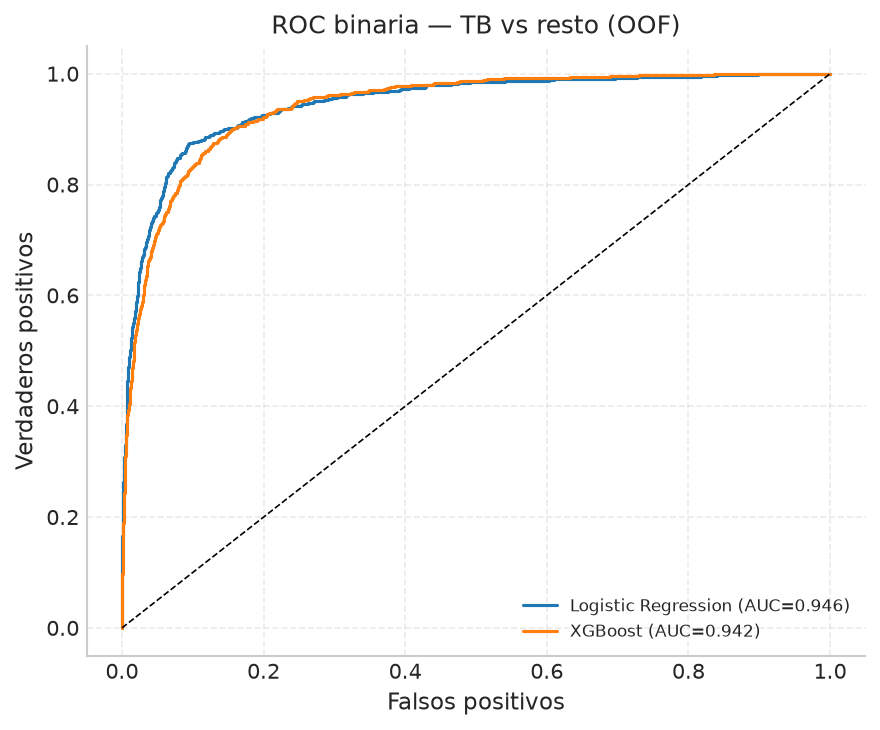

In [36]:
# Métricas binarias TB vs resto sobre las predicciones OOF.
from sklearn.metrics import roc_curve, precision_recall_curve, auc

y_tb = (y_true == 2).astype(int)
filas_bin = []

for nombre in ['Logistic Regression', 'XGBoost']:
    s = puntuaciones[nombre][:, 2]
    fpr, tpr, thr = roc_curve(y_tb, s)
    auc_roc = auc(fpr, tpr)
    ap = average_precision_score(y_tb, s)

    pred_05 = (s >= 0.5).astype(int)
    sens_05 = recall_score(y_tb, pred_05, pos_label=1)
    espec_05 = recall_score(y_tb, pred_05, pos_label=0)

    j = tpr - fpr
    k = int(np.argmax(j))
    pred_y = (s >= thr[k]).astype(int)
    sens_y = recall_score(y_tb, pred_y, pos_label=1)
    espec_y = recall_score(y_tb, pred_y, pos_label=0)

    filas_bin.append({
        'Modelo': nombre, 'AUC TB': auc_roc, 'AP TB': ap,
        'Sens@0.5': sens_05, 'Espec@0.5': espec_05,
        'Umbral Youden': thr[k], 'Sens Youden': sens_y, 'Espec Youden': espec_y,
    })

tabla_bin = pd.DataFrame(filas_bin)
tabla_bin.to_csv(DATA_DIR / '09_binario_tb.csv', index=False)
print('Métricas binarias TB vs resto (OOF):')
print(tabla_bin.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 5))
for nombre in ['Logistic Regression', 'XGBoost']:
    s = puntuaciones[nombre][:, 2]
    fpr, tpr, _ = roc_curve(y_tb, s)
    ax.plot(fpr, tpr, lw=1.5, label=f'{nombre} (AUC={auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('Falsos positivos', fontsize=11)
ax.set_ylabel('Verdaderos positivos', fontsize=11)
ax.set_title('ROC binaria — TB vs resto (OOF)', fontsize=12)
ax.legend(fontsize=8)
ax.grid(True, linestyle='--', alpha=0.4)
fig.tight_layout()
fig.savefig(REPORTS_DIR / '09_roc_binaria_tb.png', dpi=300, bbox_inches='tight')
plt.show()


## 17. Evaluación estratificada por ambigüedad del fondo

Se entrena el baseline de fondo con CV y se selecciona el 25 % de imágenes
donde el fondo está más inseguro. Si el modelo pulmonar mantiene su
rendimiento ahí, hay señal que no viene del fondo; si se hunde, era atajo.


In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

bg_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
bg_oof = np.zeros((len(y_bg), 3), dtype=float)
for tr, va in bg_cv.split(X_bg.values, y_bg, groups=groups_bg):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_bg.values[tr])
    Xva = scaler.transform(X_bg.values[va])
    clf_bg = LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE
    )
    clf_bg.fit(Xtr, y_bg[tr])
    bg_oof[va] = clf_bg.predict_proba(Xva)

ambiguedad = 1.0 - bg_oof.max(axis=1)
n_amb = max(1, int(0.25 * len(ambiguedad)))
idx_amb = np.argsort(ambiguedad)[-n_amb:]

modelo_sel = manifest['seleccionado_cv']
y_sample = y_full[idx_bg]
pred_sample = oof.iloc[idx_bg][modelo_sel].to_numpy()


def _resumen(y, pred):
    return {
        'Balanced Acc': balanced_accuracy_score(y, pred),
        'Recall TB': recall_score(
            y, pred, labels=[2], average=None, zero_division=0
        )[0],
    }


filas_estrato = [
    {'muestra': 'todas', 'n': int(len(y_sample)), **_resumen(y_sample, pred_sample)},
    {
        'muestra': 'fondo ambiguo (25 %)',
        'n': int(len(idx_amb)),
        **_resumen(y_sample[idx_amb], pred_sample[idx_amb]),
    },
]
tabla_estrato = pd.DataFrame(filas_estrato)
tabla_estrato.to_csv(DATA_DIR / '09_estratificado_fondo.csv', index=False)
print(f'Modelo pulmonar evaluado: {modelo_sel}')
print(tabla_estrato.round(4).to_string(index=False))


Modelo pulmonar evaluado: Logistic Regression
             muestra    n  Balanced Acc  Recall TB
               todas 2800        0.8696     0.7988
fondo ambiguo (25 %)  700        0.7937     0.7416


## 18. Especialista de parches de lesión

Entrena un clasificador de parches de lesión contra pulmón normal usando
las cajas de TBX11K. Se evalúa a nivel de parche y de imagen con grupos por
imagen para evitar fuga.


In [38]:
import subprocess

subprocess.run(
    [sys.executable, str(Path(PROJECT_ROOT) / 'scripts' / 'train_lesion_patches.py')],
    check=True,
)
display(pd.read_csv(DATA_DIR / 'lesion_patch_metrics.csv').round(4))


,nivel,n,AUC,AP,Balanced Acc
0,parche,4710,0.9706,0.9737,0.9178
1,imagen,2437,0.9790,0.9717,0.9371


## 19. Conclusiones de robustez

Esta sección no fija números en el texto: las conclusiones deben leerse de las
tablas y figuras generadas en esta ejecución.

- **Duplicados perceptuales:** `09_dhash.csv` y `09_dhash_resumen.json` muestran
  cuántos hashes se repiten, cuántas imágenes y grupos hay, y si la CV agrupada
  cambia el rendimiento. Los grupos con etiquetas distintas deben revisarse
  visualmente antes de tratarlos como duplicados clínicos.
- **Atajo por contexto/fuente:** el baseline de esquinas y franja inferior mide
  cuánta información predictiva hay fuera del pulmón. Si su balanced accuracy se
  aleja de 0.333, hay evidencia de sesgo de adquisición y la interpretación
  clínica debe limitarse.
- **Métricas binarias TB vs resto:** `09_binario_tb.csv` contiene AUC, AP,
  sensibilidad, especificidad y umbrales Youden/sens90 por modelo.

Para el CAD, el punto crítico es el baseline de fondo: si predice bien sin
pulmón, el modelo principal puede estar usando fuente o adquisición. Ese
resultado debe reportarse junto con las métricas globales.


## Conclusiones

Se evaluaron los cinco modelos con **predicciones out-of-fold sobre las 8256 imágenes**.
No hay hold-out ni test separado: la estimación es la validación cruzada del notebook 08.

El accuracy global está dominado por `health` y `sick`; por eso la comparación se apoya en
**balanced accuracy**, **recall de `tb`** y **AP de `tb`**. Se reportan intervalos de
confianza por bootstrap, McNemar global y restringido a `tb` (con Holm) y calibración.

Limitaciones: la CV OOF no equivale a una prueba externa independiente; no hay IDs de
paciente; y la selección de modelo y su estimación comparten las mismas predicciones OOF.
Los umbrales Youden/sens90 son orientativos y deben estimarse anidados o validarse externamente.

**Distinción explícita:** las métricas OOF son la estimación de la validación cruzada.
El modelo final (guardado en `models/`) se entrena con las 8256 imágenes; su rendimiento
en datos independientes es desconocido porque no hay test externo. La estimación del
procedimiento completo está en `08_procedimiento.json`.


**Fin del pipeline de modelado y evaluación.**
